In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import matplotlib as mpl

# 设置 Arial 字体
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# 请确认你的路径
path = r'C:\Users\13676\Desktop\senna_cohort.csv'

df = pd.read_csv(path, encoding='gb18030', encoding_errors='replace', low_memory=False)

# 处理时间列
time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

# 重建主分析集 df_main
df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)

# 确保关键变量都是数值型，防止赋分报错
for c in ['baseline_k', 'drug_count_no_laxatives', 'anticoagulant', 'insulin', 
          'beta2_agonist', 'diuretic', 'ppi', 'lactulose']:
    df_main[c] = pd.to_numeric(df_main[c], errors='coerce').fillna(0)

print(f"✅ 数据读取完成，主分析集行数: {len(df_main)}")

✅ 数据读取完成，主分析集行数: 41529


In [2]:
# 初始化得分为 0
df_main['sahrs_score'] = 0

# 1. 基线血钾赋分（最高权重）
df_main.loc[df_main['baseline_k'] < 4.0, 'sahrs_score'] += 5
df_main.loc[(df_main['baseline_k'] >= 4.0) & (df_main['baseline_k'] <= 4.5), 'sahrs_score'] += 2

# 2. 其他危险因素赋分
df_main.loc[df_main['drug_count_no_laxatives'] > 11, 'sahrs_score'] += 3
df_main.loc[df_main['anticoagulant'] == 1, 'sahrs_score'] += 3
df_main.loc[df_main['insulin'] == 1, 'sahrs_score'] += 2
df_main.loc[df_main['beta2_agonist'] == 1, 'sahrs_score'] += 2
df_main.loc[df_main['diuretic'] == 1, 'sahrs_score'] += 2
df_main.loc[df_main['ppi'] == 1, 'sahrs_score'] += 1
df_main.loc[df_main['lactulose'] == 1, 'sahrs_score'] += 1
df_main.loc[df_main['age_group'] == '85+', 'sahrs_score'] += 1
df_main.loc[df_main['senna_exposed'] == 1, 'sahrs_score'] += 1

print(f"✅ SAHRS 评分计算完成！")
print(f"分数范围: {df_main['sahrs_score'].min()} 分 到 {df_main['sahrs_score'].max()} 分")
print(f"中位数: {df_main['sahrs_score'].median()} 分")

✅ SAHRS 评分计算完成！
分数范围: 0 分 到 21 分
中位数: 10.0 分


✅ [ROC 与约登指数验证结果]
SAHRS 评分的 AUC = 0.6917
👉 最佳截断值 (Optimal Threshold) = 12 分
约登指数 (Youden Index) = 0.2765
在此切点下：敏感度 = 61.06%, 特异度 = 66.59%


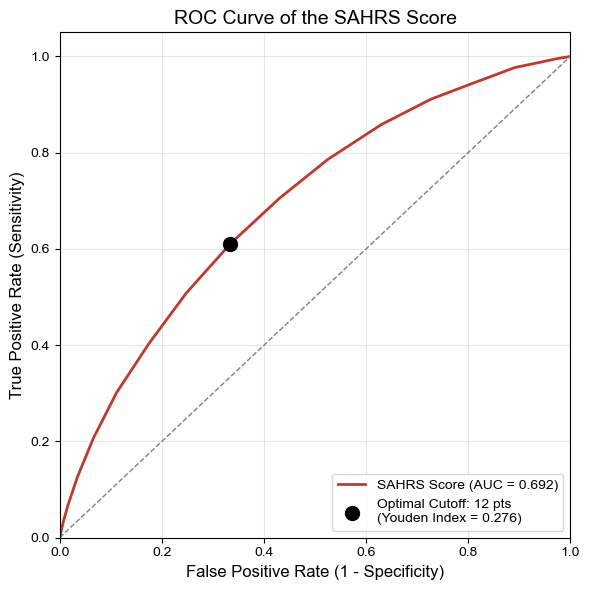

In [3]:
# 1. 计算 ROC 曲线数据
y_true = df_main['y']
y_score = df_main['sahrs_score']
fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

# 2. 计算约登指数 (Youden Index = 敏感度 + 特异度 - 1)
youden_j = tpr - fpr
max_j_index = np.argmax(youden_j)

optimal_threshold = thresholds[max_j_index]
optimal_j = youden_j[max_j_index]
optimal_sens = tpr[max_j_index]
optimal_spec = 1 - fpr[max_j_index]

print("✅ [ROC 与约登指数验证结果]")
print(f"SAHRS 评分的 AUC = {auc:.4f}")
print(f"👉 最佳截断值 (Optimal Threshold) = {optimal_threshold:.0f} 分")
print(f"约登指数 (Youden Index) = {optimal_j:.4f}")
print(f"在此切点下：敏感度 = {optimal_sens:.2%}, 特异度 = {optimal_spec:.2%}")

# 3. 绘制 ROC 曲线并高亮最佳切点
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='#C0392B', lw=2, label=f'SAHRS Score (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')

# 标记约登指数最大的那个点
plt.scatter(fpr[max_j_index], tpr[max_j_index], marker='o', color='black', s=100, zorder=5,
            label=f'Optimal Cutoff: {optimal_threshold:.0f} pts\n(Youden Index = {optimal_j:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curve of the SAHRS Score', fontsize=14)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('Figure_SAHRS_ROC.png', dpi=300, bbox_inches='tight')
plt.show()